# Camera-Based Handwriting Recognition System
### Classical Computer Vision + Shallow Multi-Layer Perceptron (MLP)
*Implementation Specification: `Informations/Camera_Based_Handwriting_Recognition_Antigravity_Spec.pdf`*

---
# Phase 1 — Image Ingestion and Document Flattening

### Objectives:
1. **Robust Optical Ingestion:** Ingest static camera captures or phone photographs (`JPEG`, `PNG`, etc.) using `cv2.imread`, clearly reporting unreadable or corrupted files.
2. **Untouched Preservation:** Retain an untouched copy of the original photograph for final bounding box and recognition HUD annotations.
3. **Optional 4-Point Perspective Transform:** Detect document paper boundaries and rectify perspective distortion via homography warp, with automatic graceful bypass if page corners cannot be reliably detected or if manual corners are specified.

In [9]:
# Import required standard and computer vision libraries for Phase 1
import os
import sys
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("=" * 60)
print("PHASE 1 ENVIRONMENT & DEPENDENCY CHECK")
print("=" * 60)
print(f"Python Version : {sys.version.split()[0]}")
print(f"OpenCV Version : {cv2.__version__}")
print(f"NumPy Version  : {np.__version__}")
print(f"Platform       : {sys.platform}")
print("=" * 60)
print("All Phase 1 libraries loaded successfully.")

PHASE 1 ENVIRONMENT & DEPENDENCY CHECK
Python Version : 3.14.3
OpenCV Version : 5.0.0
NumPy Version  : 2.5.4
Platform       : win32
All Phase 1 libraries loaded successfully.


In [10]:
class DocumentIngestionEngine:
    """
    Phase 1 Engine: Handles robust image ingestion, untouched copy preservation,
    document quadrilateral boundary detection, and optional 4-point perspective warp.
    """
    def __init__(self, enable_warp=True, min_contour_area_ratio=0.15):
        self.enable_warp = enable_warp
        self.min_contour_area_ratio = min_contour_area_ratio

    def load_image(self, file_path):
        """
        Loads an image from disk using cv2.imread and reports unreadable files clearly.
        Returns an untouched copy and dimensions.
        """
        path_obj = Path(file_path)
        if not path_obj.exists():
            raise FileNotFoundError(f"[Phase 1 Error] File not found: '{file_path}'")
        
        image = cv2.imread(str(path_obj), cv2.IMREAD_COLOR)
        if image is None or image.size == 0:
            raise ValueError(f"[Phase 1 Error] Failed to decode image. File may be corrupted or unsupported format: '{file_path}'")
        
        # Keep untouched original photo
        original_copy = image.copy()
        h, w, c = image.shape
        print(f"[Phase 1 Ingestion] Loaded '{path_obj.name}' successfully. Dimensions: {w}x{h} ({c} channels).")
        return original_copy, image

    @staticmethod
    def order_quad_points(pts):
        """
        Orders 4 corner points deterministically:
        Top-Left (min sum), Top-Right (min diff), Bottom-Right (max sum), Bottom-Left (max diff).
        """
        pts = np.array(pts, dtype="float32").reshape(4, 2)
        rect = np.zeros((4, 2), dtype="float32")

        s = pts.sum(axis=1)
        rect[0] = pts[np.argmin(s)]  # Top-Left
        rect[2] = pts[np.argmax(s)]  # Bottom-Right

        diff = np.diff(pts, axis=1)
        rect[1] = pts[np.argmin(diff)]  # Top-Right
        rect[3] = pts[np.argmax(diff)]  # Bottom-Left

        return rect

    def detect_page_corners(self, image):
        """
        Attempts to locate the four corners of a rectangular document sheet.
        Returns (corners_ordered, success_bool).
        """
        h, w = image.shape[:2]

        # Downscale for fast and noise-tolerant contour detection
        max_dim = 1000
        scale = 1.0
        if max(h, w) > max_dim:
            scale = max_dim / float(max(h, w))
            small = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
        else:
            small = image.copy()

        # Edge-focused preprocessing
        gray = cv2.cvtColor(small, cv2.COLOR_BGR2GRAY)
        blurred = cv2.GaussianBlur(gray, (5, 5), 0)
        edged = cv2.Canny(blurred, 50, 150)
        dilated = cv2.dilate(edged, cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3)), iterations=1)

        contours, _ = cv2.findContours(dilated, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return None, False

        # Sort by contour area descending
        contours = sorted(contours, key=cv2.contourArea, reverse=True)

        for c in contours[:5]:
            peri = cv2.arcLength(c, True)
            approx = cv2.approxPolyDP(c, 0.02 * peri, True)

            if len(approx) == 4 and cv2.isContourConvex(approx):
                area = cv2.contourArea(approx)
                # Verify area meets threshold relative to full frame
                if (area / (small.shape[0] * small.shape[1])) >= self.min_contour_area_ratio:
                    # Rescale corner points back to original image coordinates
                    pts = approx.reshape(4, 2) / scale
                    return self.order_quad_points(pts), True

        return None, False

    def four_point_perspective_warp(self, image, corners):
        """
        Computes perspective transform homography matrix and warps document to a flat top-down view.
        """
        rect = self.order_quad_points(corners)
        (tl, tr, br, bl) = rect

        # Compute target width
        width_a = np.linalg.norm(br - bl)
        width_b = np.linalg.norm(tr - tl)
        target_w = max(int(width_a), int(width_b))

        # Compute target height
        height_a = np.linalg.norm(tr - br)
        height_b = np.linalg.norm(tl - bl)
        target_h = max(int(height_a), int(height_b))

        # Ensure non-degenerate dimensions
        target_w = max(target_w, 100)
        target_h = max(target_h, 100)

        dst_pts = np.array([
            [0, 0],
            [target_w - 1, 0],
            [target_w - 1, target_h - 1],
            [0, target_h - 1]
        ], dtype="float32")

        # Compute perspective transform matrix
        M = cv2.getPerspectiveTransform(rect, dst_pts)
        warped = cv2.warpPerspective(image, M, (target_w, target_h), flags=cv2.INTER_CUBIC)
        return warped, M, (target_w, target_h)

    def ingest(self, image_input, manual_corners=None):
        """
        Executes Phase 1 pipeline on an image path or pre-loaded image array.
        Returns (untouched_original, processed_flattened, metadata_dict).
        """
        if isinstance(image_input, (str, Path)):
            original_copy, working_image = self.load_image(image_input)
        elif isinstance(image_input, np.ndarray):
            original_copy = image_input.copy()
            working_image = image_input.copy()
        else:
            raise TypeError(f"[Phase 1 Error] Unsupported input type: {type(image_input)}")

        meta = {
            "warp_applied": False,
            "corners": None,
            "homography_matrix": None,
            "original_shape": original_copy.shape,
            "ingested_shape": None,
        }

        # 1. Check for manual corners
        if manual_corners is not None:
            print("[Phase 1 Ingestion] Applying user-supplied manual 4-point perspective corners.")
            warped, M, (tw, th) = self.four_point_perspective_warp(working_image, manual_corners)
            meta["warp_applied"] = True
            meta["corners"] = manual_corners
            meta["homography_matrix"] = M
            meta["ingested_shape"] = warped.shape
            return original_copy, warped, meta

        # 2. Check automatic perspective warp if enabled
        if self.enable_warp:
            corners, success = self.detect_page_corners(working_image)
            if success:
                print("[Phase 1 Ingestion] Distinct document quadrilateral detected. Performing perspective rectification.")
                warped, M, (tw, th) = self.four_point_perspective_warp(working_image, corners)
                meta["warp_applied"] = True
                meta["corners"] = corners
                meta["homography_matrix"] = M
                meta["ingested_shape"] = warped.shape
                return original_copy, warped, meta
            else:
                print("[Phase 1 Ingestion] Notice: No distinct page boundary detected. Gracefully bypassing warp (using full image).")
        else:
            print("[Phase 1 Ingestion] Perspective warp disabled in configuration. Proceeding with full image.")

        meta["ingested_shape"] = working_image.shape
        return original_copy, working_image, meta

    @staticmethod
    def generate_synthetic_document_sample(width=1280, height=720):
        """
        Generates a synthetic camera capture of a slanted handwritten document on a wooden desk
        for validation and offline testing when external image files are not immediately provided.
        """
        # Create desk background
        desk = np.full((height, width, 3), (38, 48, 58), dtype=np.uint8)
        texture = np.random.normal(0, 5, (height, width, 3)).astype(np.int16)
        desk = np.clip(desk.astype(np.int16) + texture, 0, 255).astype(np.uint8)

        # Create a document sheet
        doc_w, doc_h = 700, 460
        doc = np.full((doc_h, doc_w, 3), (242, 245, 248), dtype=np.uint8)

        # Add non-uniform lighting gradient
        grad = np.linspace(0.88, 1.04, doc_w).reshape(1, -1, 1)
        doc = np.clip(doc.astype(np.float32) * grad, 0, 255).astype(np.uint8)

        # Draw sample handwriting
        font = cv2.FONT_HERSHEY_SCRIPT_SIMPLEX
        cv2.putText(doc, "Camera-Based Recognition", (40, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (80, 80, 80), 2, cv2.LINE_AA)
        cv2.putText(doc, "Phase 1: Ingestion Stream", (40, 130), cv2.FONT_HERSHEY_SIMPLEX, 0.8, (100, 100, 100), 2, cv2.LINE_AA)
        cv2.putText(doc, "The quick brown fox", (45, 220), font, 1.8, (25, 25, 25), 4, cv2.LINE_AA)
        cv2.putText(doc, "jumps over 40928 dogs", (45, 330), font, 1.8, (20, 20, 20), 4, cv2.LINE_AA)
        cv2.putText(doc, "ANTIGRAVITY 2026", (45, 410), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (40, 40, 40), 2, cv2.LINE_AA)

        # Warp document onto desk with perspective tilt
        src_pts = np.array([[0, 0], [doc_w, 0], [doc_w, doc_h], [0, doc_h]], dtype="float32")
        dst_pts = np.array([[220, 110], [1060, 80], [1120, 620], [160, 580]], dtype="float32")
        M = cv2.getPerspectiveTransform(src_pts, dst_pts)
        warped_doc = cv2.warpPerspective(doc, M, (width, height), flags=cv2.INTER_LINEAR)

        # Mask composite
        mask = np.zeros((height, width), dtype=np.uint8)
        cv2.fillConvexPoly(mask, dst_pts.astype(np.int32), 255)
        desk_bg = cv2.bitwise_and(desk, desk, mask=cv2.bitwise_not(mask))
        synthetic_frame = cv2.add(desk_bg, warped_doc)

        return synthetic_frame, dst_pts


[Phase 1 Ingestion] Distinct document quadrilateral detected. Performing perspective rectification.
Original Input Dimensions    : 1280x720
Flattened Document Dimensions : 960x544
Perspective Rectification    : Applied


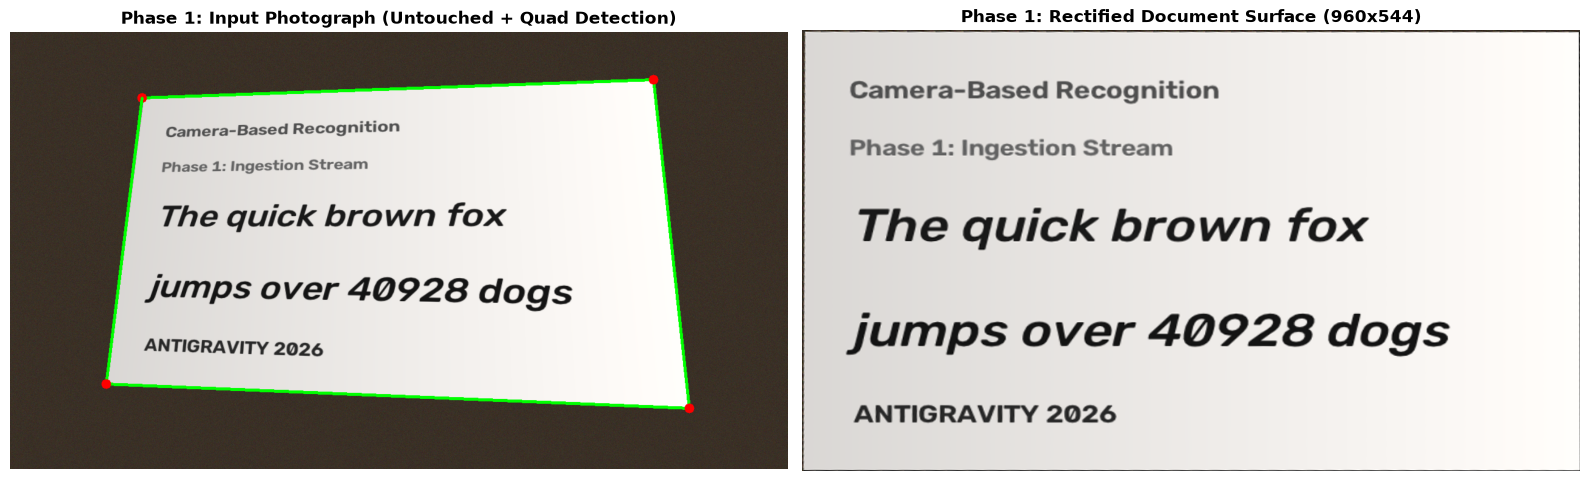

In [ ]:
# 1. Initialize Phase 1 Ingestion Engine
ingestion_engine = DocumentIngestionEngine(enable_warp=True, min_contour_area_ratio=0.15)

# 2. Acquire sample input (synthetic tilted document camera capture)
sample_frame, true_corners = DocumentIngestionEngine.generate_synthetic_document_sample()

# Save sample to data/samples for persistent reference
sample_path = Path("data/samples/sample_camera_capture.png")
sample_path.parent.mkdir(parents=True, exist_ok=True)
cv2.imwrite(str(sample_path), sample_frame)

# 3. Ingest frame through Phase 1 pipeline
original_img, flattened_doc, meta = ingestion_engine.ingest(sample_frame)

# 4. Assert integrity guarantees
assert original_img is not None, "Original image must not be None"
assert flattened_doc is not None, "Ingested document must not be None"
assert original_img.shape == sample_frame.shape, "Original image must preserve input dimensions"
print(f"Original Input Dimensions    : {original_img.shape[1]}x{original_img.shape[0]}")
print(f"Flattened Document Dimensions : {flattened_doc.shape[1]}x{flattened_doc.shape[0]}")
print(f"Perspective Rectification    : {'Applied' if meta['warp_applied'] else 'Bypassed (Direct Pass)'}")

# 5. Visual Display: Original Photo vs Rectified Document
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left: Original Untouched Camera Capture with detected quad overlay
display_orig = cv2.cvtColor(original_img, cv2.COLOR_BGR2RGB)
if meta["warp_applied"] and meta["corners"] is not None:
    pts = meta["corners"].astype(np.int32)
    for i in range(4):
        p1 = tuple(pts[i])
        p2 = tuple(pts[(i + 1) % 4])
        cv2.line(display_orig, p1, p2, (0, 255, 0), 3)
        cv2.circle(display_orig, p1, 8, (255, 0, 0), -1)

axes[0].imshow(display_orig)
axes[0].set_title("Phase 1: Input Photograph (Untouched + Quad Detection)", fontsize=12, fontweight="bold")
axes[0].axis("off")

# Right: Rectified / Flattened Document Surface
axes[1].imshow(cv2.cvtColor(flattened_doc, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Phase 1: Rectified Document Surface ({flattened_doc.shape[1]}x{flattened_doc.shape[0]})", fontsize=12, fontweight="bold")
axes[1].axis("off")

plt.tight_layout()
plt.show()
